# Phase 1: Technical Data Profiling & Quality Audit
**Objective:**
    Inspect the 4 raw data dumps from legacy ISP systems (`CRM`, `Prepaid Recharges`, `Technical Support`, and `Landline Billing`) to identify schema mismatches, data quality
    issues, and entity relationships before designing the PostgreSQL database schema.

### Entity Relationship & Grain Overview
- **`crm_subscribers.csv`**: 1 row per subscriber contract (`Primary Key`: `subscriber_id`).
- **`internet_recharges.csv`**: 1 row per recharge attempt (`Foreign Key`: `subscriber_id`).
- **`technical_tickets.csv`**: 1 row per support ticket (`Foreign Key`: `subscriber_id`).
- **`fixe_billing.csv`**: 1 row per bi-monthly landline invoice (`Foreign Key`: `landline_number` referencing `crm_subscribers.landline_number`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

---
## 1. CRM Subscribers Audit (`crm_subscribers.csv`)

In [2]:
df = pd.read_csv("../data/raw/crm_subscribers.csv")     

df.head(10)

,subscriber_id,landline_number,wilaya,plan_type,speed_mbps,monthly_price_dzd,install_date,modem_model,acquisition_channel
0,SUB-10566,41999001,Oran,Idoom_Fibre,20,2200,2021-04-07,Huawei_HG8245H,Door_to_Door
1,SUB-11101,31920840,CONSTANTINE,Idoom_Fibre,50,2600,2023-06-29,ZTE_F660,Commercial_Agency
2,SUB-11475,21531081,16 - Alger,Idoom_Fibre,15 Mbps,2000,2021-06-29,Nokia_G240W,Online_Portal
3,SUB-11178,41115559,31 - Oran,Idoom_Fibre,100,3000,2022-10-30,Nokia_G240W,Commercial_Agency
4,SUB-11009,45811226,29 - Mascara,Idoom_ADSL,15,2000,2022-03-09,DLink_DSL2750U,Commercial_Agency
5,SUB-10433,21297900,16 - Alger,Idoom_Fibre,300,4200,2022-02-06,Nokia_G240W,Commercial_Agency
6,SUB-10855,21149703,16 - Alger,Idoom_ADSL,20,2200,2021-04-18,DLink_DSL2750U,Online_Portal
7,SUB-11493,31136849,25 - Constantine,Idoom_Fibre,15 Mbps,2000,2023-10-20,Nokia_G240W,Door_to_Door
8,SUB-11032,21126276,Algiers,Idoom_ADSL,15,2000,2021-05-16,DLink_DSL2750U,Commercial_Agency
9,SUB-11079,31806242,CONSTANTINE,Idoom_Fibre,100,3000,2023-12-18,ZTE_F660,Door_to_Door


In [3]:
df.shape
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1523 entries, 0 to 1522
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   subscriber_id        1523 non-null   str  
 1   landline_number      1523 non-null   int64
 2   wilaya               1523 non-null   str  
 3   plan_type            1523 non-null   str  
 4   speed_mbps           1491 non-null   str  
 5   monthly_price_dzd    1523 non-null   int64
 6   install_date         1523 non-null   str  
 7   modem_model          1523 non-null   str  
 8   acquisition_channel  1523 non-null   str  
dtypes: int64(2), str(7)
memory usage: 107.2 KB


,landline_number,monthly_price_dzd
count,1.523000e+03,1523.000000
mean,3.293069e+07,2433.880499
std,9.592920e+06,552.245307
min,2.110051e+07,2000.000000
25%,2.171646e+07,2000.000000
50%,3.179186e+07,2200.000000
75%,4.167307e+07,2600.000000
max,4.599016e+07,4200.000000


In [4]:
df.duplicated().sum()

np.int64(23)

In [5]:
df.isnull().sum()

subscriber_id           0
landline_number         0
wilaya                  0
plan_type               0
speed_mbps             32
monthly_price_dzd       0
install_date            0
modem_model             0
acquisition_channel     0
dtype: int64

In [6]:
df['wilaya'].value_counts()

wilaya
Algiers             157
16 - Alger          139
ORAN                138
Alger               134
31 - Oran           132
ALGIERS             128
Oran                122
oran                121
CONSTANTINE          98
25 - Constantine     88
Constantine          84
29 - Mascara         49
MASCARA              49
mascara              43
Mascara              41
Name: count, dtype: int64

### Findings — `crm_subscribers`:
1. **Duplicate Records:** `23` exact duplicate rows detected out of `1,523` total rows (`1,500` unique subscribers). Action: Deduplicate on `subscriber_id`.
2. **Missing & Corrupted `speed_mbps`:** Stored as string (`str`) due to `" Mbps"` suffixes (e.g., `"15 Mbps"`), with `32` missing values (`NaN`). Action: Strip text, cast to `INTEGER`, and impute missing speeds deterministically using `monthly_price_dzd` mapping (`2000->15`, `2200->20`, `2600->50`, `3000->100`, `4200->300`).
3. **Inconsistent `wilaya` Formatting:** `15` distinct string variations representing only `4` actual wilayas (`Algiers`, `Oran`, `Constantine`, `Mascara`). Action: Standardize strings.
4. **Landline Number Type Mismatch:** `landline_number` is parsed as `int64`, stripping the leading zero (`021`, `031`, `041`, `045`). Action: Cast to `VARCHAR` and prepend `'0'`.

---
## 2. Prepaid Internet Recharges Audit (`internet_recharges.csv`)

In [7]:
df2= pd.read_csv("../data/raw/internet_recharges.csv")     

df2.head(10)

,tx_id,subscriber_id,timestamp,amount_dzd,payment_method,tx_status,days_granted
0,TX-500001,SUB-10000,2025-01-06 11:41:00,2000,Agency_Cash,SUCCESS,30
1,TX-500002,SUB-10000,2025-02-10 10:25:00,2000,Agency_Cash,SUCCESS,30
2,TX-500003,SUB-10000,2025-03-23 09:57:00,2000,Agency_Cash,SUCCESS,30
3,TX-500004,SUB-10000,2025-05-04 13:46:00,2000,Agency_Cash,SUCCESS,30
4,TX-500005,SUB-10000,2025-06-14 14:48:00,2000,Agency_Cash,SUCCESS,30
5,TX-500006,SUB-10000,2025-07-27 21:01:00,2000,CIB_Online,SUCCESS,30
6,TX-500007,SUB-10001,2025-01-18 09:51:00,2000,Edahabia_Online,SUCCESS,30
7,TX-500008,SUB-10001,2025-02-19 17:22:00,2000,Edahabia_Online,SUCCESS,30
8,TX-500009,SUB-10001,2025-03-21 14:26:00,2000,CIB_Online,SUCCESS,30
9,TX-500010,SUB-10001,2025-04-20 11:10:00,2000,CIB_Online,SUCCESS,30


In [8]:
df2.shape
df2.info()
df2.describe()

<class 'pandas.DataFrame'>
RangeIndex: 16210 entries, 0 to 16209
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   tx_id           16210 non-null  str  
 1   subscriber_id   16210 non-null  str  
 2   timestamp       16210 non-null  str  
 3   amount_dzd      16210 non-null  int64
 4   payment_method  16210 non-null  str  
 5   tx_status       16210 non-null  str  
 6   days_granted    16210 non-null  int64
dtypes: int64(2), str(5)
memory usage: 886.6 KB


,amount_dzd,days_granted
count,16210.000000,16210.000000
mean,2438.729180,28.693399
std,554.452186,6.123164
min,2000.000000,0.000000
25%,2000.000000,30.000000
50%,2200.000000,30.000000
75%,2600.000000,30.000000
max,4200.000000,30.000000


In [9]:
df2.isnull().sum()

tx_id             0
subscriber_id     0
timestamp         0
amount_dzd        0
payment_method    0
tx_status         0
days_granted      0
dtype: int64

In [10]:
df2.duplicated().sum()

np.int64(0)

In [11]:
df2['payment_method'].value_counts()

payment_method
Agency_Cash        6976
Edahabia_Online    4632
CIB_Online         4602
Name: count, dtype: int64

<Axes: xlabel='tx_status'>

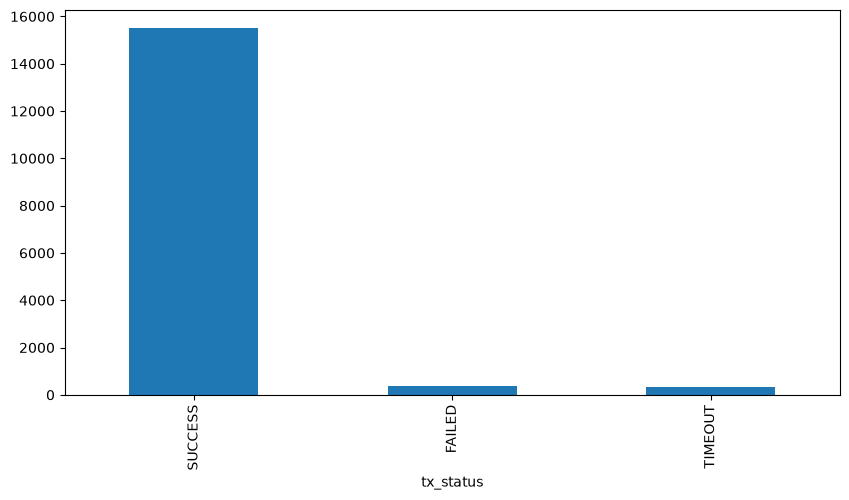

In [12]:
df2['tx_status'].value_counts().plot(kind='bar', figsize=(10, 5))

In [13]:
df2['days_granted'].value_counts()

days_granted
30    15504
0       706
Name: count, dtype: int64

### Findings — `internet_recharges`:
1. **Completeness & Uniqueness:** `16,210` total rows with `0` nulls and `0` duplicates.
2. **Failed/Timeout Transactions:** Contains `15,504` successful recharges (`days_granted = 30`) and `706` unsuccessful attempts (`FAILED` or `TIMEOUT` with `days_granted = 0`). Note: `amount_dzd` records the requested amount even on failed attempts; revenue and cycle calculations must filter for `tx_status == 'SUCCESS'`.
3. **Data Types:** `timestamp` is stored as string (`str`) and must be cast to `TIMESTAMP`.

---
## 3. Technical Support Tickets Audit (`technical_tickets.csv`)

In [14]:
df3= pd.read_csv("../data/raw/technical_tickets.csv")

df3.head(10)

,ticket_id,subscriber_id,opened_at,closed_at,issue_category,line_attenuation_db
0,TKT-90001,SUB-10000,2025-01-05 10:00:00,2025-01-08 16:05:02,Modem_Sync,20.7
1,TKT-90002,SUB-10002,2025-05-21 14:00:00,2025-05-23 01:03:13,Billing_Dispute,16.5
2,TKT-90003,SUB-10002,2025-05-29 15:00:00,2025-05-31 17:55:45,Modem_Sync,18.5
3,TKT-90004,SUB-10005,2025-11-19 15:00:00,2025-11-23 07:25:02,High_Attenuation,28.8
4,TKT-90005,SUB-10005,2025-07-14 11:00:00,2025-07-18 06:09:25,Fixe_No_Dialtone,33.2
5,TKT-90006,SUB-10005,2025-07-10 18:00:00,2025-07-16 05:20:57,Fibre_Cut,27.2
6,TKT-90007,SUB-10009,2025-02-20 13:00:00,2025-02-25 20:58:13,Fixe_No_Dialtone,16.4
7,TKT-90008,SUB-10009,2025-11-05 19:00:00,2025-11-10 13:33:10,Modem_Sync,15.2
8,TKT-90009,SUB-10010,2025-06-06 12:00:00,2025-06-11 17:19:37,Billing_Dispute,18.4
9,TKT-90010,SUB-10010,2025-01-09 17:00:00,2025-01-13 10:14:33,Billing_Dispute,18.3


In [15]:
df3.shape
df3.info()
df3.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1828 entries, 0 to 1827
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ticket_id            1828 non-null   str    
 1   subscriber_id        1828 non-null   str    
 2   opened_at            1828 non-null   str    
 3   closed_at            1732 non-null   str    
 4   issue_category       1828 non-null   str    
 5   line_attenuation_db  1828 non-null   float64
dtypes: float64(1), str(5)
memory usage: 85.8 KB


,line_attenuation_db
count,1828.000000
mean,24.994420
std,6.262862
min,8.500000
25%,19.300000
50%,26.600000
75%,30.100000
max,39.600000


In [16]:
(df3['closed_at'] < df3['opened_at']).sum()

np.int64(51)

In [17]:
df3['issue_category'].value_counts()

issue_category
Fibre_Cut           456
Modem_Sync          415
High_Attenuation    385
Fixe_No_Dialtone    342
Billing_Dispute     230
Name: count, dtype: int64

### Findings — `technical_tickets`:
1. **Unresolved Tickets (`NaN`):** Out of `1,828` tickets, `closed_at` has `96` null values (`1,732` non-null), representing currently open/unresolved support tickets.
2. **Inverted Timestamps (`closed_at < opened_at`):** `51` corrupted records have a closure timestamp earlier than the opening timestamp. Action: Keep the ticket record and `line_attenuation_db` measurement, but nullify (`NULL`) the invalid `closed_at` value during ETL cleaning.
3. **Signal Attenuation (`line_attenuation_db`):** Ranges from `8.5 dB` to `39.6 dB` with a median of `26.6 dB`, indicating significant physical line degradation among complaining subscribers.

---
## 4. Landline Billing Audit (`fixe_billing.csv`)

In [18]:
df4= pd.read_csv("../data/raw/fixe_billing.csv")

df4.head(10)

,invoice_id,landline_number,billing_cycle,fixe_fee_dzd,voice_calls_dzd,total_due_dzd,payment_status,paid_date
0,INV-700001,31494990,2025-B1,500,0,500,PAID,2025-02-11
1,INV-700002,31494990,2025-B2,500,0,500,PAID,2025-04-09
2,INV-700003,31494990,2025-B3,500,150,650,PAID,2025-06-14
3,INV-700004,31494990,2025-B4,500,0,500,PAID,2025-08-13
4,INV-700005,31494990,2025-B5,500,1200,1700,UNPAID,NaN
5,INV-700006,31494990,2025-B6,500,0,500,UNPAID,NaN
6,INV-700007,21550316,2025-B1,500,0,500,PAID,2025-02-09
7,INV-700008,21550316,2025-B2,500,1200,1700,PAID,2025-04-13
8,INV-700009,21550316,2025-B3,500,320,820,PAID,2025-06-14
9,INV-700010,21550316,2025-B4,500,680,1180,PAID,2025-08-09


In [19]:
df4.shape
df4.info()
df4.describe()

<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   invoice_id       9000 non-null   str  
 1   landline_number  9000 non-null   int64
 2   billing_cycle    9000 non-null   str  
 3   fixe_fee_dzd     9000 non-null   int64
 4   voice_calls_dzd  9000 non-null   int64
 5   total_due_dzd    9000 non-null   int64
 6   payment_status   9000 non-null   str  
 7   paid_date        7829 non-null   str  
dtypes: int64(4), str(4)
memory usage: 562.6 KB


,landline_number,fixe_fee_dzd,voice_calls_dzd,total_due_dzd
count,9.000000e+03,9000.0,9000.000000,9000.000000
mean,3.295810e+07,500.0,386.531111,886.531111
std,9.596067e+06,0.0,426.434122,426.434122
min,2.110051e+07,500.0,0.000000,500.000000
25%,2.171652e+07,500.0,0.000000,500.000000
50%,3.180090e+07,500.0,150.000000,650.000000
75%,4.168104e+07,500.0,680.000000,1180.000000
max,4.599016e+07,500.0,1200.000000,1700.000000


In [20]:
df4.duplicated().sum()

np.int64(0)

In [21]:
df4.isnull().sum()

invoice_id            0
landline_number       0
billing_cycle         0
fixe_fee_dzd          0
voice_calls_dzd       0
total_due_dzd         0
payment_status        0
paid_date          1171
dtype: int64

In [22]:
df4['payment_status'].value_counts()

payment_status
PAID      6792
UNPAID    1171
LATE      1037
Name: count, dtype: int64

### Findings — `fixe_billing`:
1. **Completeness & Structure:** `9,000` total invoices (`1,500` subscribers × `6` bi-monthly billing cycles `2025-B1` to `2025-B6`), with `0` duplicates.
2. **Unpaid Invoices (`NaN` Alignment):** `paid_date` has exactly `1,171` missing values, which matches the `1,171` invoices with `payment_status == 'UNPAID'`. These nulls are valid business states and must be preserved as `NULL` in PostgreSQL.
3. **Foreign Key Formatting:** `landline_number` is parsed as `int64` (missing leading `'0'`). Must be formatted as `VARCHAR` with a leading zero to join cleanly with `crm_subscribers(landline_number)`.